In [ ]:
# Basic libraries
import numpy as np                      # arrays of numbers (our images)
import matplotlib.pyplot as plt         # graphs and showing images
import urllib.request, os               # downloading the .npy files

# PyTorch (deep learning)
import torch                             # The core PyTorch library for tensor operations
import torch.nn as nn                    # Contains building blocks like layers (Linear, Conv2d) and loss functions
import torch.nn.functional as F          # Provides functional operations like activations (ReLU) and pooling
import torchvision                       # gives us ResNet-50 and image transforms

# TensorDataset: Wraps features and labels into a single dataset object
# DataLoader: Handles mini-batching, shuffling, and parallel data loading
from torch.utils.data import TensorDataset, DataLoader

# For splitting data into train / validation / test
from sklearn.model_selection import train_test_split

# Use the GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

# Results of every experiment will be stored here
results = {}

Using: cuda


In [ ]:
categories = [
    # 1-10
    "apple", "banana", "cat", "dog", "car", "house", "tree", "star", "sun", "fish",
    # 11-20
    "bicycle", "airplane", "clock", "cloud", "cup", "eye", "flower", "guitar", "hammer", "hat",
    # 21-30
    "key", "ladder", "leaf", "mushroom", "pizza", "rainbow", "scissors", "shoe", "snake", "umbrella",
    # 31-50
    "book", "bird", "butterfly", "camera", "candle", "chair", "crown", "donut", "door", "envelope",
    "eyeglasses", "fork", "giraffe", "helicopter", "ice cream", "light bulb", "lollipop", "mountain", "octopus", "pencil",
    # 51-100
    "rabbit", "sailboat", "shark", "snowman", "spoon", "strawberry", "table", "television", "toothbrush", "truck",
    "watermelon", "windmill", "zebra", "ant", "axe", "basketball", "bee", "bridge", "cactus", "carrot",
    "circle", "cookie", "crab", "elephant", "feather", "frog", "grapes", "hourglass", "lion", "monkey",
    "owl", "pear", "penguin", "piano", "pig", "pineapple", "skull", "snail", "sock", "spider",
    "square", "suitcase", "swan", "teapot", "tent", "tornado", "trumpet", "violin", "whale", "wine glass",
]
print("Number of categories:", len(categories))

Number of categories: 100


In [ ]:
data = {}   # data["apple"] = 1000 drawings of apples, each 28x28

for name in categories:
    url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/" + name.replace(" ", "%20") + ".npy"
    urllib.request.urlretrieve(url, "temp.npy")                    # download the file

    drawings = np.load("temp.npy", mmap_mode="r")                  # shape: (number of drawings, 784)
    pick = np.random.RandomState(42).choice(len(drawings), 1000, replace=False)   # 1000 random ones
    data[name] = drawings[np.sort(pick)].reshape(-1, 28, 28)       # 784 numbers -> 28 x 28 image

    print(f"{name:12s} total drawings: {len(drawings):,}  -> kept 1000")
    del drawings
    os.remove("temp.npy")                                          # delete the big file

apple        total drawings: 144,722  -> kept 1000
banana       total drawings: 307,936  -> kept 1000
cat          total drawings: 123,202  -> kept 1000
dog          total drawings: 152,159  -> kept 1000
car          total drawings: 182,764  -> kept 1000
house        total drawings: 135,420  -> kept 1000
tree         total drawings: 144,721  -> kept 1000
star         total drawings: 137,619  -> kept 1000
sun          total drawings: 133,781  -> kept 1000
fish         total drawings: 134,150  -> kept 1000
bicycle      total drawings: 126,527  -> kept 1000
airplane     total drawings: 151,623  -> kept 1000
clock        total drawings: 120,536  -> kept 1000
cloud        total drawings: 120,265  -> kept 1000
cup          total drawings: 130,721  -> kept 1000
eye          total drawings: 125,888  -> kept 1000
flower       total drawings: 144,818  -> kept 1000
guitar       total drawings: 120,451  -> kept 1000
hammer       total drawings: 119,012  -> kept 1000
hat          total drawings: 22

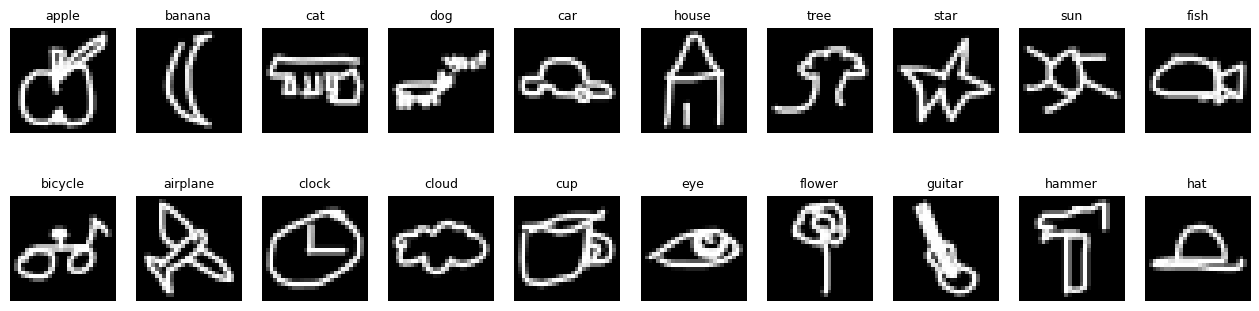

In [ ]:
# One drawing from each of the first 20 categories
plt.figure(figsize=(16, 4))
for i in range(20):
    plt.subplot(2, 10, i + 1)
    plt.imshow(data[categories[i]][0], cmap="gray")   # white strokes on black background
    plt.title(categories[i], fontsize=9)
    plt.axis("off")
plt.show()

In [ ]:
N = 10              # number of categories (the first 10 in our list)
EPOCHS = 15         # paper: 15 epochs for 10 categories
BATCH_SIZE = 64     # paper: batch size 64
LR = 1e-5           # paper: learning rate 0.00001

In [ ]:
# Stack all drawings into one array, and make a label for each drawing
# label 0 = apple, 1 = banana, 2 = cat, ... 9 = fish
X = np.concatenate([data[c] for c in categories[:N]])        # shape: (10000, 28, 28)
y = np.concatenate([np.full(1000, i) for i in range(N)])     # shape: (10000,)

# Split: 80% train, 10% validation, 10% test (same as the paper)
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

# Convert to PyTorch tensors
# pixels 0..255 -> 0..1, and add a channel dimension: (28, 28) -> (1, 28, 28)
X_train = torch.tensor(X_train).float().div(255).unsqueeze(1)
X_val = torch.tensor(X_val).float().div(255).unsqueeze(1)
X_test = torch.tensor(X_test).float().div(255).unsqueeze(1)
y_train, y_val, y_test = torch.tensor(y_train), torch.tensor(y_val), torch.tensor(y_test)

# DataLoaders feed the model 64 images at a time
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)

print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

Train: 8000 | Validation: 1000 | Test: 1000


In [ ]:
# ImageNet mean and std (the pretrained weights expect images normalized like this)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# Augmentation for training images only (same as the paper)
augment = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),   # flip left-right half the time
    torchvision.transforms.RandomRotation(10),       # rotate between -10 and +10 degrees
])

In [ ]:
model = torchvision.models.resnet50(weights="IMAGENET1K_V1")   # standard ResNet-50, ImageNet weights
model.fc = nn.Linear(2048, N)                                   # new last layer: 2048 features -> 10 categories
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()                                 # paper: cross-entropy loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)        # paper: AdamW optimizer

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


In [ ]:
train_losses, train_accs, val_losses, val_accs = [], [], [], []

for epoch in range(EPOCHS):

    # ----- TRAINING: the model learns -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        images = torch.stack([augment(img) for img in images])                    # random flip / rotate
        images = F.interpolate(images, size=(224, 224), mode="bilinear")          # resize 28x28 -> 224x224
        images = images.repeat(1, 3, 1, 1)                                        # 1 gray channel -> 3 channels
        images = (images - mean) / std                                            # normalize

        outputs = model(images)                  # forward pass: one score per category
        loss = loss_fn(outputs, labels)          # how wrong the scores are

        optimizer.zero_grad()                    # clear old gradients
        loss.backward()                          # backward pass: compute gradients
        optimizer.step()                         # update the weights

        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()   # highest score = predicted category
        total += len(labels)

    train_losses.append(total_loss / total)
    train_accs.append(100 * correct / total)

    # ----- VALIDATION: check on images the model is not trained on -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():                        # no learning here
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = F.interpolate(images, size=(224, 224), mode="bilinear")
            images = images.repeat(1, 3, 1, 1)
            images = (images - mean) / std

            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)

    val_losses.append(total_loss / total)
    val_accs.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train loss {train_losses[-1]:.4f}, acc {train_accs[-1]:.2f}% "
          f"| Val loss {val_losses[-1]:.4f}, acc {val_accs[-1]:.2f}%")

Epoch 1/15 | Train loss 1.3470, acc 71.05% | Val loss 0.5939, acc 88.20%
Epoch 2/15 | Train loss 0.4634, acc 89.09% | Val loss 0.3150, acc 91.60%
Epoch 3/15 | Train loss 0.2976, acc 92.41% | Val loss 0.2285, acc 93.10%
Epoch 4/15 | Train loss 0.2353, acc 93.47% | Val loss 0.2187, acc 93.20%
Epoch 5/15 | Train loss 0.1983, acc 94.22% | Val loss 0.2031, acc 93.60%
Epoch 6/15 | Train loss 0.1696, acc 95.09% | Val loss 0.1973, acc 93.50%
Epoch 7/15 | Train loss 0.1471, acc 95.62% | Val loss 0.1890, acc 94.10%
Epoch 8/15 | Train loss 0.1293, acc 96.22% | Val loss 0.1817, acc 94.00%
Epoch 9/15 | Train loss 0.1135, acc 96.53% | Val loss 0.1805, acc 94.20%
Epoch 10/15 | Train loss 0.1070, acc 96.79% | Val loss 0.1850, acc 93.90%
Epoch 11/15 | Train loss 0.0893, acc 97.29% | Val loss 0.1932, acc 93.90%
Epoch 12/15 | Train loss 0.0795, acc 97.67% | Val loss 0.1896, acc 93.80%
Epoch 13/15 | Train loss 0.0750, acc 97.88% | Val loss 0.1981, acc 94.30%
Epoch 14/15 | Train loss 0.0643, acc 98.06% | V

In [ ]:
model.eval()
total_loss, correct, total = 0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        images = F.interpolate(images, size=(224, 224), mode="bilinear")
        images = images.repeat(1, 3, 1, 1)
        images = (images - mean) / std

        outputs = model(images)
        total_loss += loss_fn(outputs, labels).item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

print(f"TEST ({N} categories): accuracy {100 * correct / total:.2f}%, loss {total_loss / total:.4f}")
print(f"PAPER (ResNet-50, 10 categories): accuracy 94.60%, loss 0.1815")

TEST (10 categories): accuracy 95.50%, loss 0.1479
PAPER (ResNet-50, 10 categories): accuracy 94.60%, loss 0.1815


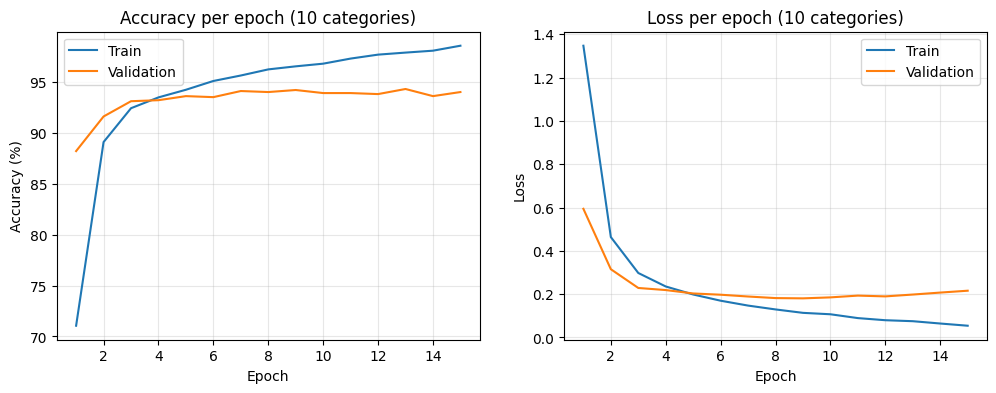

In [ ]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accs, label="Train")
plt.plot(epochs, val_accs, label="Validation")
plt.title("Accuracy per epoch (10 categories)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, val_losses, label="Validation")
plt.title("Loss per epoch (10 categories)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)

plt.show()

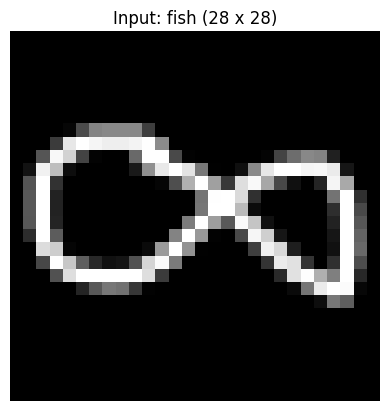

After conv1: (1, 64, 112, 112)


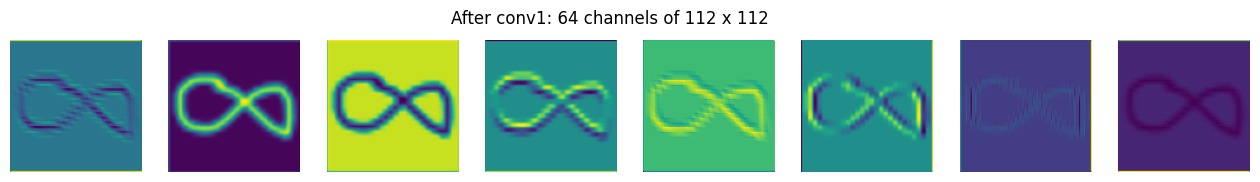

After bn1: (1, 64, 112, 112)


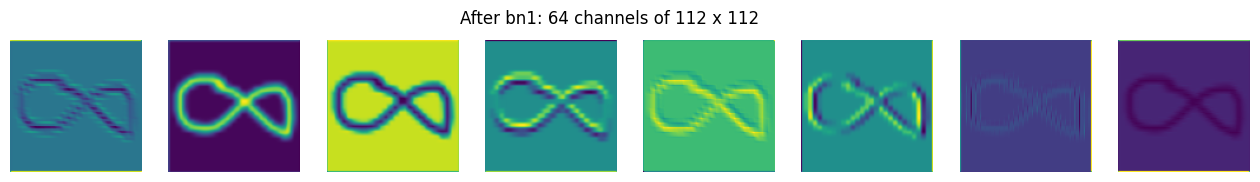

After relu: (1, 64, 112, 112)


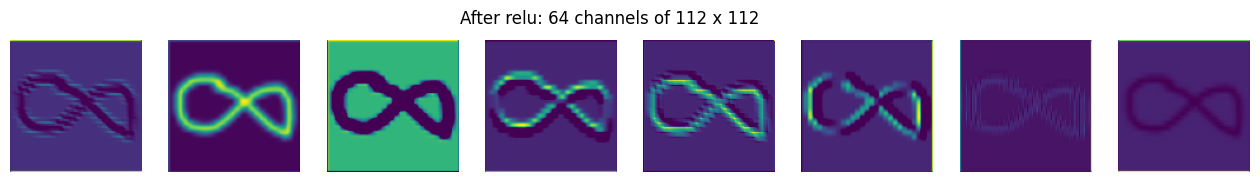

After maxpool: (1, 64, 56, 56)


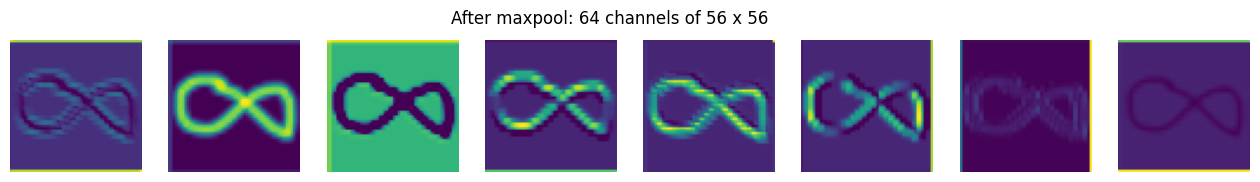

After layer1: (1, 256, 56, 56)


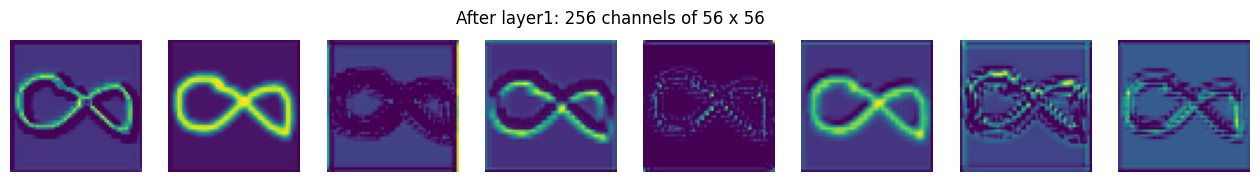

After layer2: (1, 512, 28, 28)


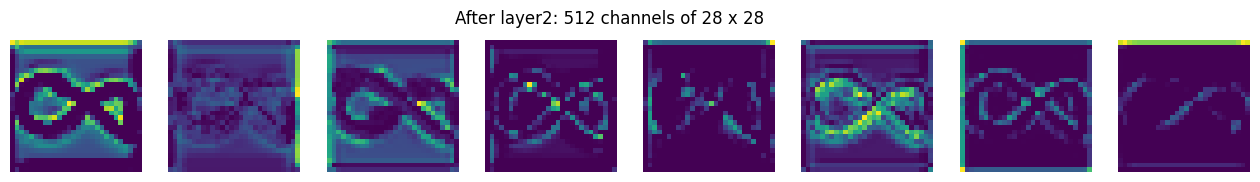

After layer3: (1, 1024, 14, 14)


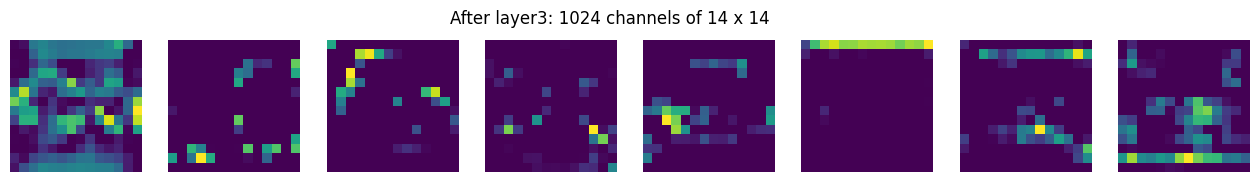

After layer4: (1, 2048, 7, 7)


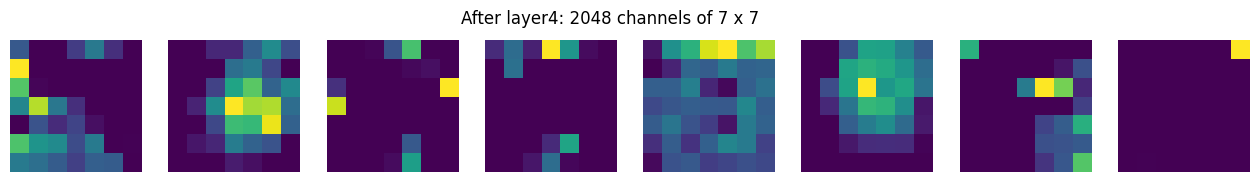

After avgpool: (1, 2048)
After fc: (1, 10)
Prediction: fish


In [ ]:
# Find the first fish in the test set
fish_index = (y_test == categories.index("fish")).nonzero()[0].item()
image = X_test[fish_index:fish_index + 1].to(device)                     # shape: (1, 1, 28, 28)

plt.imshow(image[0, 0].cpu(), cmap="gray"); plt.title("Input: fish (28 x 28)"); plt.axis("off"); plt.show()

# Prepare it exactly like the training images
x = F.interpolate(image, size=(224, 224), mode="bilinear")
x = x.repeat(1, 3, 1, 1)
x = (x - mean) / std

# The layers of ResNet-50, in order
layers = [("conv1", model.conv1), ("bn1", model.bn1), ("relu", model.relu), ("maxpool", model.maxpool),
          ("layer1", model.layer1), ("layer2", model.layer2), ("layer3", model.layer3), ("layer4", model.layer4)]

model.eval()
with torch.no_grad():
    for name, layer in layers:
        x = layer(x)                                         # pass through ONE layer
        print(f"After {name}: {tuple(x.shape)}")              # (batch, channels, height, width)

        plt.figure(figsize=(16, 2))
        for i in range(8):                                   # show the first 8 channels
            plt.subplot(1, 8, i + 1)
            plt.imshow(x[0, i].cpu(), cmap="viridis")
            plt.axis("off")
        plt.suptitle(f"After {name}: {x.shape[1]} channels of {x.shape[2]} x {x.shape[3]}")
        plt.show()

    x = model.avgpool(x)                  # each 7x7 map -> 1 number  (2048 numbers)
    x = torch.flatten(x, 1)
    print("After avgpool:", tuple(x.shape))
    x = model.fc(x)                       # 2048 numbers -> 10 category scores
    print("After fc:", tuple(x.shape))
    print("Prediction:", categories[x.argmax(1).item()])

In [ ]:
!pip install -q "gradio<6"
import gradio as gr
import base64, io
from PIL import Image, ImageFilter

# =====================================================================
# RESNET-50 × QUICK, DRAW!  ·  live doodle recognition web app
# Uses the 10-category model that is already trained and in memory.
# =====================================================================
N = 10
ACCURACY = "95.50%"
model.eval()

# ---------------------------------------------------------------------
# 1. PREDICTION: turns the drawing into a 28x28 Quick Draw-style image,
#    runs ResNet-50 and builds the two result panels
# ---------------------------------------------------------------------
def to_data_url(arr):
    """numpy image -> base64 PNG string an <img> tag can show"""
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

EMPTY_RESULT = """
<div class='empty pred-box'><i class='fa-solid fa-wand-magic-sparkles'></i>
<div>Start drawing.<br>The prediction updates with every stroke.</div></div>"""
EMPTY_SEEN = """
<div class='empty seen-box'><i class='fa-regular fa-eye'></i>
<div>Your drawing, shrunk to the 28 × 28 pixels the model was trained on.</div></div>"""

def predict(drawing):
    if drawing is None:
        return EMPTY_RESULT, EMPTY_SEEN
    img = drawing["composite"] if isinstance(drawing, dict) else drawing
    if img is None:
        return EMPTY_RESULT, EMPTY_SEEN
    img = np.array(img).astype(np.float32)
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)

    # find the ink: works for a transparent or a solid canvas, any brush colour
    if img.shape[2] == 4 and img[:, :, 3].min() < 250:
        ink = img[:, :, 3]                                        # painted pixels are opaque
    else:
        rgb = img[:, :, :3]
        border = np.concatenate([rgb[0], rgb[-1], rgb[:, 0], rgb[:, -1]])
        background = np.median(border, axis=0)                    # canvas colour
        ink = np.abs(rgb - background).max(axis=2)                # how different from the canvas
    if ink.max() < 30:
        return EMPTY_RESULT, EMPTY_SEEN

    # crop to the drawing and centre it in a square (white ink on black, like Quick Draw)
    rows, cols = np.where(ink > 30)
    ink = ink[rows.min():rows.max() + 1, cols.min():cols.max() + 1]
    h, w = ink.shape
    side = max(h, w)
    pad = int(side * 0.08) + 1
    square = np.zeros((side + 2 * pad, side + 2 * pad), dtype=np.float32)
    top, left = (square.shape[0] - h) // 2, (square.shape[1] - w) // 2
    square[top:top + h, left:left + w] = ink

    # shrink to 28 x 28, exactly the size of the training images
    pil = Image.fromarray(square.clip(0, 255).astype(np.uint8))
    pil = pil.resize((112, 112), Image.LANCZOS).filter(ImageFilter.MaxFilter(3))   # thicken strokes
    small = np.array(pil.resize((28, 28), Image.LANCZOS))

    # same preparation as training: 224 x 224, 3 channels, ImageNet normalisation
    x = torch.tensor(small).float().div(255).view(1, 1, 28, 28).to(device)
    x = F.interpolate(x, size=(224, 224), mode="bilinear").repeat(1, 3, 1, 1)
    x = (x - mean) / std
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0].cpu()

    # --- panel 2: final prediction + top 3 ---
    top3 = probs.topk(3)
    best, conf = categories[int(top3.indices[0])], float(top3.values[0])
    bars = ""
    for rank, (p, i) in enumerate(zip(top3.values, top3.indices), start=1):
        pct = float(p) * 100
        bars += (f"<div class='bar-row{' first' if rank == 1 else ''}'>"
                 f"<span class='rank'>{rank:02d}</span>"
                 f"<span class='rname'>{categories[int(i)]}</span>"
                 f"<div class='track'><div class='fill' style='width:{pct:.1f}%'></div></div>"
                 f"<span class='rval'>{pct:.1f}%</span></div>")
    result = (f"<div class='result pred-box'>"
              f"<div class='eyebrow'>Final prediction</div>"
              f"<div class='pred'>{best}</div>"
              f"<div class='conf'><b>{conf * 100:.1f}%</b> confidence</div>"
              f"<div class='eyebrow mt'>Top 3 guesses</div>{bars}</div>")

    # --- panel 3: what the model sees ---
    big = np.array(Image.fromarray(small).resize((280, 280), Image.NEAREST))
    seen = (f"<div class='seen-box'><div class='seen'><img src='{to_data_url(big)}' alt='28 by 28 input'></div>"
            f"<div class='steps'><span>Crop</span><i class='fa-solid fa-chevron-right'></i>"
            f"<span>28 × 28</span><i class='fa-solid fa-chevron-right'></i>"
            f"<span>224 × 224 × 3</span><i class='fa-solid fa-chevron-right'></i>"
            f"<span class='hl'>ResNet-50</span></div></div>")
    return result, seen

# ---------------------------------------------------------------------
# 2. ARTWORK: black & white street art / doodle photos from Unsplash
# ---------------------------------------------------------------------
PHOTOS = ["1589287707312-213624549c88", "1612147552704-52e1858c7c47", "1494026222377-872a605b54ba",
          "1624681558383-2311be2d3f56", "1576096876569-0cffb1b1268d", "1457877916676-133b53113613",
          "1611562242695-cc5940964622", "1558285043-7d82c6b6cc6d", "1555432384-3b2fa7b650c9",
          "1586149216537-ffac0fc7abf3", "1596268600847-f67818526b9b", "1571445750952-20a9793f77ce",
          "1552354460-714fe3de22dc", "1591200806549-318b668d6e77"]

def photo(pid, w=600, h=400):
    return (f"<img src='https://images.unsplash.com/photo-{pid}?auto=format&fit=crop&w={w}&h={h}&q=80' "
            f"alt='' loading='lazy' onerror=\"this.style.display='none'\">")

def strip(ids, reverse=False):
    items = "".join(photo(p) for p in ids)
    return f"<div class='strip{' rev' if reverse else ''}'><div class='track-x'>{items}{items}</div></div>"

# ---------------------------------------------------------------------
# 3. PAGE SECTIONS (HTML)
# ---------------------------------------------------------------------
HEADER = f"""
<div class='nav'>
  <div class='brand'><span class='logo'><i class='fa-solid fa-layer-group'></i></span>Doodle <b>Recognition</b></div>
</div>
<div class='hero'>
  <div class='hero-text'>
    <div class='tag'><i class='fa-solid fa-bolt'></i>Live demo · Deep learning</div>
    <div class='title'>ResNet-50<br><span>× Quick, Draw!</span></div>
    <div class='sub'>Sketch a doodle and watch a 50-layer residual network, fine-tuned on
      Google's Quick, Draw! dataset, recognise it in real time.</div>
    <div class='stats'>
      <div class='stat'><div class='num'>{ACCURACY}</div><div class='lbl'><i class='fa-solid fa-bullseye'></i>Test accuracy</div></div>
      <div class='stat'><div class='num'>{N}</div><div class='lbl'><i class='fa-solid fa-shapes'></i>Categories</div></div>
      <div class='stat'><div class='num'>50</div><div class='lbl'><i class='fa-solid fa-layer-group'></i>Layers deep</div></div>
      <div class='stat'><div class='num'>10K</div><div class='lbl'><i class='fa-solid fa-database'></i>Doodles used</div></div>
    </div>
  </div>
  <div class='hero-art'>
    <div class='a1'>{photo(PHOTOS[0], 700, 900)}</div>
    <div class='a2'>{photo(PHOTOS[1], 600, 450)}</div>
    <div class='a3'>{photo(PHOTOS[2], 600, 450)}</div>
  </div>
</div>
{strip(PHOTOS[3:])}
<div class='chips'>
  <span class='chips-label'><i class='fa-solid fa-pencil'></i>Draw one of these</span>
  {''.join(f"<span class='chip'>{c}</span>" for c in categories[:N])}
</div>
"""

def card_head(num, icon, title, hint):
    return (f"<div class='card-head'><span class='num'>{num}</span>"
            f"<span class='ico'><i class='{icon}'></i></span>"
            f"<span class='ttl'>{title}</span><span class='hint'>{hint}</span></div>")

FOOTER = f"""
{strip(PHOTOS[::-1], reverse=True)}
<div class='foot'>
  <div class='who'>
    <span class='name'>Hrishikesh Gavai</span>
    <a href='https://github.com/Hrishikesh-Gavai' target='_blank' rel='noopener' aria-label='GitHub' title='GitHub'><i class='fa-brands fa-github'></i></a>
    <a href='https://in.linkedin.com/in/hrishikesh-gavai' target='_blank' rel='noopener' aria-label='LinkedIn' title='LinkedIn'><i class='fa-brands fa-linkedin-in'></i></a>
  </div>
  <div class='built'>ResNet-50 · PyTorch · Quick, Draw! dataset · Photos: Unsplash</div>
</div>
"""

# ---------------------------------------------------------------------
# 4. STYLE: #000000, #FFFFFF and neon yellow #E6FF00 (pink only for text selection)
# ---------------------------------------------------------------------
HEAD = """<link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.5.2/css/all.min.css">"""

theme = gr.themes.Base(
    primary_hue="yellow", neutral_hue="zinc",
    font=[gr.themes.GoogleFont("Space Grotesk"), "sans-serif"],
    font_mono=[gr.themes.GoogleFont("JetBrains Mono"), "monospace"],
).set(
    body_background_fill="#000000", body_background_fill_dark="#000000",
    body_text_color="#FFFFFF", body_text_color_dark="#FFFFFF",
    background_fill_primary="#000000", background_fill_primary_dark="#000000",
    background_fill_secondary="#000000", background_fill_secondary_dark="#000000",
    block_background_fill="#000000", block_background_fill_dark="#000000",
    block_border_width="0px", block_radius="0px",
    border_color_primary="#FFFFFF", border_color_primary_dark="#FFFFFF",
    color_accent="#E6FF00", color_accent_soft="#E6FF00",
    block_label_text_color="#FFFFFF", block_label_text_color_dark="#FFFFFF",
    block_label_background_fill="#000000", block_label_background_fill_dark="#000000",
    body_text_color_subdued="#FFFFFF", body_text_color_subdued_dark="#FFFFFF",
)

CSS = """
:root { --y:#E6FF00; --b:#000000; --w:#FFFFFF; }
footer { display:none !important; }
::selection { background:#FF2E88 !important; color:#FFFFFF !important; }
::-moz-selection { background:#FF2E88 !important; color:#FFFFFF !important; }
*::selection { background:#FF2E88 !important; color:#FFFFFF !important; }
.gradio-container { max-width:100% !important; width:100% !important; background:#000 !important; padding:8px 3vw 0 !important; }
.prose, .prose * { color:inherit; }

/* nav */
.nav { display:flex; justify-content:space-between; align-items:center; padding:14px 2px 18px; border-bottom:1px solid #fff; }
.brand { display:flex; align-items:center; gap:10px; font-size:20px; letter-spacing:.5px; color:#fff; }
.brand b { color:var(--y); }
.logo { width:34px; height:34px; display:inline-flex; align-items:center; justify-content:center; background:var(--y); color:#000; }

/* hero */
.hero { display:grid; grid-template-columns:1.25fr 1fr; gap:36px; padding:40px 2px 34px; align-items:center; }
.tag { display:inline-flex; align-items:center; gap:8px; background:var(--y); color:#000; font-weight:700; font-size:13px; text-transform:uppercase; letter-spacing:1.5px; padding:6px 12px; }
.title { font-size:76px; line-height:.95; font-weight:700; letter-spacing:-2px; margin:20px 0 18px; color:#fff; }
.title span { color:var(--y); }
.sub { font-size:18px; line-height:1.55; color:#fff; max-width:680px; }
.stats { display:grid; grid-template-columns:repeat(4,1fr); margin-top:30px; border:1px solid #fff; }
.stat { padding:16px 16px 14px; border-right:1px solid #fff; }
.stat:last-child { border-right:0; }
.stat .num { font-family:var(--font-mono); font-size:28px; font-weight:700; color:var(--y); }
.stat .lbl { font-size:12px; text-transform:uppercase; letter-spacing:1.2px; margin-top:6px; color:#fff; display:flex; gap:7px; align-items:center; }
.hero-art { display:grid; grid-template-columns:1.1fr 1fr; grid-template-rows:1fr 1fr; gap:10px; height:440px; }
.hero-art div { overflow:hidden; border:1px solid #fff; background:#000; }
.hero-art .a1 { grid-row:1 / span 2; }
.hero-art img { width:100%; height:100%; object-fit:cover; display:block; filter:grayscale(100%) contrast(1.15); transition:transform .6s ease; }
.hero-art div:hover img { transform:scale(1.05); }

/* scrolling photo strips */
.strip { overflow:hidden; border-top:1px solid #fff; border-bottom:1px solid #fff; background:#000; margin:8px 0; }
.track-x { display:flex; gap:0; width:max-content; animation:scrollx 70s linear infinite; }
.strip.rev .track-x { animation-direction:reverse; }
.strip img { height:130px; width:200px; object-fit:cover; display:block; filter:grayscale(100%) contrast(1.2); border-right:1px solid #000; }
@keyframes scrollx { from{transform:translateX(0)} to{transform:translateX(-50%)} }

/* category chips */
.chips { display:flex; flex-wrap:wrap; align-items:center; gap:8px; padding:22px 2px 10px; }
.chips-label { color:var(--y); font-weight:700; font-size:13px; text-transform:uppercase; letter-spacing:1.5px; margin-right:6px; display:inline-flex; gap:8px; align-items:center; }
.chip { border:1px solid #fff; color:#fff; padding:6px 14px; font-size:14px; text-transform:capitalize; transition:all .2s; }
.chip:hover { background:var(--y); color:#000; border-color:var(--y); }

/* the 3 cards */
.card { background:#000 !important; border:1px solid #fff !important; border-radius:0 !important; padding:20px !important; gap:14px !important; }
.right-col { display:flex !important; flex-direction:column !important; gap:16px !important; }
.right-col > .card { flex:1 1 auto !important; }
.card-head { display:flex; align-items:center; gap:12px; padding-bottom:14px; border-bottom:1px solid #fff; }
.card-head .num { font-family:var(--font-mono); font-size:12px; color:var(--y); letter-spacing:1px; }
.card-head .ico { width:30px; height:30px; display:inline-flex; align-items:center; justify-content:center; background:var(--y); color:#000; font-size:14px; }
.card-head .ttl { font-size:17px; font-weight:700; text-transform:uppercase; letter-spacing:1.5px; color:#fff; }
.card-head .hint { margin-left:auto; font-size:12px; color:#fff; opacity:.75; }

/* fixed panel heights: the boxes stay the same size before and after you draw */
.pred-box { min-height:310px; }
.seen-box { min-height:290px; display:flex; flex-direction:column; justify-content:center; }
.empty { display:flex; flex-direction:column; align-items:center; justify-content:center; gap:14px; text-align:center; color:#fff; font-size:14px; line-height:1.5; }
.empty i { font-size:26px; color:var(--y); }

/* drawing toolbar icons: white, neon when active */
#sketch button, #sketch button svg, #sketch [role='button'] { color:#FFFFFF !important; }
#sketch button:hover, #sketch button:hover svg, #sketch button.selected, #sketch button.selected svg, #sketch button[aria-pressed='true'] svg { color:#E6FF00 !important; }
#sketch button { background:transparent !important; border-color:#FFFFFF !important; }

/* keep only the pen (plus undo / clear): hide eraser, colour picker and brush-size controls */
#sketch [aria-label*="eras" i], #sketch [title*="eras" i],
#sketch [aria-label*="color" i], #sketch [title*="color" i], #sketch [aria-label*="colour" i],
#sketch [aria-label*="size" i], #sketch [title*="size" i],
#sketch input[type="range"], #sketch input[type="color"],
#sketch .color-picker, #sketch .colors, #sketch .brush-options, #sketch .brush-size { display:none !important; }

/* swap the brush icon for a neon pencil */
#sketch button[aria-label*="brush" i] svg, #sketch button[title*="brush" i] svg,
#sketch button[aria-label*="draw" i] svg, #sketch button[title*="draw" i] svg { display:none !important; }
#sketch button[aria-label*="brush" i]::after, #sketch button[title*="brush" i]::after,
#sketch button[aria-label*="draw" i]::after, #sketch button[title*="draw" i]::after {
  content:"\\f303"; font-family:"Font Awesome 6 Free"; font-weight:900; font-size:15px; color:#E6FF00; }

/* prediction panel */
.eyebrow { font-family:var(--font-mono); font-size:11px; text-transform:uppercase; letter-spacing:2px; color:#fff; opacity:.8; }
.eyebrow.mt { margin-top:22px; margin-bottom:6px; }
.pred { display:inline-block; margin-top:10px; background:var(--y); color:#000; font-size:46px; font-weight:700; text-transform:uppercase; letter-spacing:-1px; line-height:1; padding:8px 16px 6px; }
.conf { margin-top:10px; font-size:15px; color:#fff; }
.conf b { color:var(--y); font-family:var(--font-mono); }
.bar-row { display:grid; grid-template-columns:28px 92px 1fr 62px; align-items:center; gap:10px; padding:9px 0; border-bottom:1px solid #fff; }
.bar-row:last-child { border-bottom:0; }
.rank { font-family:var(--font-mono); font-size:12px; color:#fff; opacity:.8; }
.rname { font-size:15px; text-transform:capitalize; color:#fff; font-weight:600; }
.track { height:10px; border:1px solid #fff; background:#000; }
.fill { height:100%; background:#fff; transition:width .35s ease; }
.bar-row.first .fill { background:var(--y); }
.bar-row.first .track { border-color:var(--y); }
.bar-row.first .rname, .bar-row.first .rval { color:var(--y); }
.rval { font-family:var(--font-mono); font-size:13px; text-align:right; color:#fff; }

/* model input panel */
.seen { display:flex; justify-content:center; padding:6px 0; }
.seen img { width:210px; height:210px; image-rendering:pixelated; border:1px solid #fff; }
.steps { display:flex; flex-wrap:wrap; justify-content:center; align-items:center; gap:8px; margin-top:14px; font-family:var(--font-mono); font-size:11px; text-transform:uppercase; letter-spacing:1px; color:#fff; }
.steps span { border:1px solid #fff; padding:4px 8px; }
.steps span.hl { background:var(--y); color:#000; border-color:var(--y); }
.steps i { font-size:9px; color:var(--y); }

/* footer */
.foot { display:flex; justify-content:space-between; align-items:center; flex-wrap:wrap; gap:14px; padding:22px 2px 30px; }
.who { display:flex; align-items:center; gap:14px; }
.who .name { font-size:20px; font-weight:700; color:#fff; }
.who a { width:40px; height:40px; display:inline-flex; align-items:center; justify-content:center; border:1px solid #fff; color:#fff !important; font-size:17px; text-decoration:none !important; transition:all .2s; }
.who a:hover { background:var(--y); color:#000 !important; border-color:var(--y); }
.built { font-family:var(--font-mono); font-size:12px; text-transform:uppercase; letter-spacing:1px; color:#fff; opacity:.8; }

@media (max-width: 900px) {
  .hero { grid-template-columns:1fr; }
  .hero-art { height:280px; }
  .title { font-size:52px; }
  .stats { grid-template-columns:repeat(2,1fr); }
  .stat:nth-child(2) { border-right:0; }
  .stat:nth-child(-n+2) { border-bottom:1px solid #fff; }
}
"""

# ---------------------------------------------------------------------
# 5. BUILD THE PAGE
# ---------------------------------------------------------------------
with gr.Blocks(theme=theme, css=CSS, head=HEAD, title="ResNet-50 × Quick, Draw!") as demo:
    gr.HTML(HEADER)
    with gr.Row(equal_height=True):
        with gr.Column(scale=7, elem_classes="card"):                       # BOX 1: draw
            gr.HTML(card_head("01", "fa-solid fa-pen-nib", "Draw", "Use undo or the bin to start over"))
            sketch = gr.Sketchpad(
                elem_id="sketch", show_label=False, container=False, type="numpy", image_mode="RGBA", height=700,
                brush=gr.Brush(colors=["#E6FF00"], color_mode="fixed", default_size=22),   # thick neon-yellow pen
                eraser=False,                                                         # no eraser
            )
        with gr.Column(scale=5, elem_classes="right-col"):
            with gr.Column(elem_classes="card"):                            # BOX 2: prediction
                gr.HTML(card_head("02", "fa-solid fa-brain", "Prediction", "Live"))
                result = gr.HTML(EMPTY_RESULT)
            with gr.Column(elem_classes="card"):                            # BOX 3: model input
                gr.HTML(card_head("03", "fa-regular fa-eye", "What the model sees", "28 × 28 input"))
                seen = gr.HTML(EMPTY_SEEN)
    gr.HTML(FOOTER)

    sketch.change(fn=predict, inputs=sketch, outputs=[result, seen])          # update on every stroke

demo.launch(share=True)

/tmp/ipykernel_400/2179060994.py:316: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=theme, css=CSS, head=HEAD, title="ResNet-50 × Quick, Draw!") as demo:
/tmp/ipykernel_400/2179060994.py:316: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(theme=theme, css=CSS, head=HEAD, title="ResNet-50 × Quick, Draw!") as demo:
/tmp/ipykernel_400/2179060994.py:316: DeprecationWarning: The 'head' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'head' to Blocks.launch() instead.
  with gr.Blocks(theme=theme, css=CSS, head=HEAD, title="ResNet-50 × Quick, Draw!") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://47f1203463fd124425.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
